# LLM Fine Tuning · Lesson 9 · Distillation: a large model's behaviour in a small one

Lessons 4 and 5 trained a model on **gold answers**. Often there are none: a team has the questions (from logs) and a
large model that answers them well enough, but no human-written answers, and the large model is too slow or too costly to
serve. Distillation moves the large model's behaviour into a small one. This lab does it on the course task (a question about
a table in, one SQLite query out) with a teacher and a student from the same family, and measures what it gives and what it costs.

- **Teacher:** Qwen2.5-7B-Instruct in 4-bit (lesson 5 loaded it and measured it zero-shot).
- **Student:** Qwen2.5-0.5B-Instruct, about fifteen times fewer parameters, trained with LoRA (lesson 4's recipe).
- **Data:** training questions only. The teacher writes the answers; the gold answers are used for diagnosis, never for training the distilled student.

The questions, each answered by the measurement that follows it:

1. **How big is the gap?** Student and teacher on the same 500 test questions, with time and memory.
2. **What does the teacher cost to ask?** Labelling a pool of training questions, timed.
3. **Are the teacher's labels usable?** A program filter (the query must run in SQLite against its schema) and its keep rate.
4. **Why can one answer stand for a distribution?** How much probability the teacher puts on its own answer.
5. **Does the student learn it?** Distilled student against the untrained student, a student trained on gold answers for the same questions, and the teacher.
6. **What did the filter buy, and how many labels are enough?** Filtered against unfiltered, and a short learning curve.
7. **What does it cost and when does it pay back?** GPU-seconds per 1,000 answers, and a break-even.
8. **Does the student inherit the teacher's mistakes?**

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. Estimate (not a measurement): about 50 minutes
in total: 3 for set-up and data, 5 for the first download and load of the 7B teacher (15 GB), 3 for the teacher on the test set,
15 for the teacher to label the pool, 12 for the three student trainings and the learning curve, 5 for scoring the students,
the rest for the smaller measurements. The labelling time is the size knob: lower `N_LABEL` in section 0 if your session is shorter.
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/3-beyond-sft/09-distillation).

## 0. Install, load and rebuild the lesson 3 splits

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored.

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
# bitsandbytes 0.50.2 is the version that worked with Colab's CUDA 13 runtime; 0.45.5 did not.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 trl==0.19.1 datasets==3.6.0 bitsandbytes==0.50.2

In [2]:
import gc
import json
import os
import random
import re
import sqlite3
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import Dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed
from trl import SFTConfig, SFTTrainer

%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

SEED = 42
set_seed(SEED)
TEACHER_ID = "Qwen/Qwen2.5-7B-Instruct"      # lesson 5's 7B model, loaded in 4-bit
STUDENT_ID = "Qwen/Qwen2.5-0.5B-Instruct"    # the same family, about fifteen times smaller
DEVICE = "cuda"
DTYPE = torch.float16        # a T4 has no bfloat16 (lesson 2)
N_TEST = 500                 # held-out examples every system is scored on (the same 500 as lessons 4 and 5)
N_LABEL = 3000               # training questions the teacher answers: the size knob (about 15 minutes, estimate)
LABEL_BATCH = 32             # labelling is batch work, so it uses a larger batch than the latency measurements
RUN_CURVE = True             # also train on the first half and quarter of the labels (about 5 minutes, estimate)
N_FID = 64                   # test questions used for the token-level comparison in section 4
N_SINGLE = 12                # test questions timed one at a time
GB = 1e9
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0), f"| {torch.cuda.get_device_properties(0).total_memory / GB:.1f} GB")

transformers 4.51.3 | trl 0.19.1 | peft 0.15.2
GPU: Tesla T4 | 15.6 GB


The data is rebuilt here with the same code and the same seed as lessons 3 to 5, so this lab runs on its own: drop gold
queries that fail in SQLite, drop exact duplicates, then split **by table** (5% test, 5% validation, the rest
training). The counts must match lesson 3: 69,170 training, 3,817 validation and 3,923 test examples. The dataset is
`b-mc2/sql-create-context` (CC BY 4.0), built from WikiSQL and Spider.

In [3]:
# Pinned to the same commit of the dataset as lesson 3.
URL = ("https://huggingface.co/datasets/b-mc2/sql-create-context/resolve/"
       "9d80a6a118b838d9defc3798d659a54a2ac2ff37/sql_create_context_v4.json")
data = pd.DataFrame(json.load(urllib.request.urlopen(URL)))


def runs(context, sql):
    """Return None if the query runs against the schema, or the SQLite error message."""
    con = sqlite3.connect(":memory:")
    try:
        for statement in context.split(";"):
            if statement.strip():
                con.execute(statement)
        con.execute(sql)
        return None
    except sqlite3.Error as e:
        return str(e)
    finally:
        con.close()


norm = lambda s: re.sub(r"\s+", " ", s.strip().lower())
data["error"] = [runs(c, a) for c, a in zip(data["context"], data["answer"])]

# A split group is one named table. WikiSQL's re-used names (table_name_N) are groups of one.
table = data["context"].str.extract(r"CREATE TABLE (\w+)")[0].fillna("")
named = ~table.str.fullmatch(r"table_name_\d+")
data["group"] = np.where(named, table, "row" + data.index.astype(str))

clean = data[data["error"].isna()].drop_duplicates(["question", "context", "answer"]).reset_index(drop=True)
uniq = np.random.default_rng(SEED).permutation(clean["group"].unique())
n = len(uniq)
split_of = {u: ("test" if i < 0.05 * n else "validation" if i < 0.10 * n else "train") for i, u in enumerate(uniq)}
clean["split"] = clean["group"].map(split_of)
print(clean["split"].value_counts().to_string())
assert clean["split"].value_counts().to_dict() == {"train": 69170, "test": 3923, "validation": 3817}, "differs from lesson 3"

SYSTEM = "You write SQLite queries. Answer with one SQL query and nothing else."


def messages(r):
    """One example in conversational prompt-completion form, as TRL's SFTTrainer expects it."""
    return {
        "prompt": [{"role": "system", "content": SYSTEM},
                   {"role": "user", "content": f"Schema:\n{r['context']}\n\nQuestion: {r['question']}"}],
        "completion": [{"role": "assistant", "content": r["answer"]}],
    }


rows = {s: clean[clean["split"] == s].to_dict("records") for s in ["train", "validation", "test"]}

split
train         69170
test           3923
validation     3817


The scoring code is lesson 4's, with two additions: `evaluate` also records the peak GPU memory while answering, and
`generate` can be called with another batch size. Decoding is greedy. **runs** means the generated SQL executes in SQLite
against the `CREATE TABLE` schema (the tables are empty, so this says the query is valid for the schema, not that it is
right). **exact** means the SQL equals the gold query after normalisation. Replies are cleaned only by removing a
Markdown code fence if the model adds one. The test set is the same 500 examples as lessons 4 and 5: same seed, same sample.

In [4]:
test = random.Random(SEED).sample(rows["test"], N_TEST)


def zero_shot(r):
    return messages(r)["prompt"]


def clean_sql(text):
    """Strip white space and a Markdown code fence, if the model wrote one."""
    text = text.strip()
    text = re.sub(r"^```(?:sql)?\s*|\s*```$", "", text, flags=re.I).strip()
    return text


def normalise(sql):
    sql = re.sub(r"\s+", " ", sql.strip().lower()).strip()
    return sql.rstrip(";").strip().replace('"', "'")


def score(rows_, generated):
    """Per-example 'runs' and 'exact' for a list of generated answers."""
    out = []
    for r, g in zip(rows_, generated):
        sql = clean_sql(g)
        error = "empty answer" if not sql else runs(r["context"], sql)
        out.append({"sql": sql, "error": error, "runs": error is None,
                    "exact": normalise(sql) == normalise(r["answer"])})
    return pd.DataFrame(out)


@torch.inference_mode()
def generate(model, tok, prompts, batch=16, max_new_tokens=128):
    """Greedy answers for a list of chat prompts, batched with left padding. Returns (answers, ms per example)."""
    model.generation_config.update(temperature=None, top_p=None, top_k=None)

    def run(chunk, n_new):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in chunk]
        enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=n_new, do_sample=False, pad_token_id=tok.pad_token_id)
        return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

    run(prompts[:2], 4)                        # warm-up, so start-up cost is not timed
    answers, start = [], time.perf_counter()
    for i in range(0, len(prompts), batch):
        answers += run(prompts[i:i + batch], max_new_tokens)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return answers, 1000 * (time.perf_counter() - start) / len(prompts)


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


def footprint(model):
    """Parameter storage in GB by dtype. A 4-bit weight is stored packed in uint8, so its size here is real."""
    by = {}
    for p in model.parameters():
        key = str(p.dtype).replace("torch.", "")
        by[key] = by.get(key, 0) + p.numel() * p.element_size() / GB
    return {k: round(v, 2) for k, v in sorted(by.items())}


def evaluate(name, model, tok, single=False):
    """Score a model on the 500 test examples (batch 16) and store runs, exact, ms per example and peak GPU memory.
    With single=True also time N_SINGLE answers one request at a time (batch 1)."""
    free_gpu()
    torch.cuda.reset_peak_memory_stats()
    answers, ms = generate(model, tok, [zero_shot(r) for r in test])
    peak = torch.cuda.max_memory_allocated() / GB
    scored[name] = score(test, answers)
    results[name] = {"runs": scored[name]["runs"].mean(), "exact": scored[name]["exact"].mean(),
                     "ms per example": ms, "weights GB": sum(footprint(model).values()), "serving peak GB": peak}
    if single:
        results[name]["ms single"] = generate(model, tok, [zero_shot(r) for r in test[:N_SINGLE]], batch=1)[1]
    print(f"{name:30s} runs {results[name]['runs']:.1%}  exact {results[name]['exact']:.1%}  {ms:.0f} ms per example "
          f"(batch 16)  weights {results[name]['weights GB']:.2f} GB  peak {peak:.2f} GB")


tok = AutoTokenizer.from_pretrained(STUDENT_ID, padding_side="left")
tok_teacher = AutoTokenizer.from_pretrained(TEACHER_ID, padding_side="left")
assert tok.get_vocab() == tok_teacher.get_vocab(), "teacher and student must share a tokeniser for section 4"
results, scored, train_stats = {}, {}, {}

## 1. How big is the gap?

Two measurements on the same 500 test questions with the zero-shot prompt (the one the distilled student will see):

- the **student** untrained, in fp16 (about 1 GB of weights);
- the **teacher**, loaded in 4-bit as in lesson 5 (the 15 GB download happens here).

Besides exact match, each model is timed two ways: 500 answers in batches of 16 (a loaded server) and 12 answers one at a time
(a lone request), and its peak GPU memory while answering is read. The teacher is a 4-bit model, so each decode step rebuilds
its weights to fp16: its time includes that cost, as in lesson 5. Both stay in memory after this section: the teacher is
needed for labelling, and the student's number is the one to beat.

In [5]:
free_gpu()
student0 = AutoModelForCausalLM.from_pretrained(STUDENT_ID, torch_dtype=DTYPE, device_map={"": DEVICE}).eval()
print("student parameters:", f"{sum(p.numel() for p in student0.parameters()) / 1e6:.0f}M", footprint(student0))
evaluate("student zero-shot", student0, tok, single=True)
del student0
free_gpu()

student parameters: 494M {'float16': 0.99}


student zero-shot              runs 92.8%  exact 44.0%  108 ms per example (batch 16)  weights 0.99 GB  peak 1.09 GB


In [6]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

free_gpu()
# device_map takes the GPU number (0), not "cuda": accelerate 1.6.0 reads the index of a 4-bit model's device
# and fails on "cuda", which has none (lesson 5).
teacher = AutoModelForCausalLM.from_pretrained(TEACHER_ID, quantization_config=bnb_config,
                                               torch_dtype=DTYPE, device_map={"": 0}).eval()
print("teacher parameters:", f"{sum(p.numel() for p in teacher.parameters()) / 1e6:.0f}M stored (4-bit weights are packed)",
      footprint(teacher))
evaluate("teacher", teacher, tok, single=True)
print("(lesson 5 measured this model zero-shot at runs and exact match on the same 500 questions; "
      "the number above is this session's)")

teacher parameters: 4353M stored (4-bit weights are packed) {'float16': 2.18, 'uint8': 3.26}


teacher                        runs 98.6%  exact 65.2%  388 ms per example (batch 16)  weights 5.44 GB  peak 6.01 GB
(lesson 5 measured this model zero-shot at runs and exact match on the same 500 questions; the number above is this session's)


The two rows are the gap to close, and the price of the teacher's side of it in time and memory. Nothing has been trained yet.

## 2. What does the teacher cost to ask?

The realistic setting: there are questions and no gold answers. `N_LABEL` training questions are drawn at random from the
training split, and the teacher answers each one with the same prompt as above. **This is sequence-level distillation:** the
student will be trained on the teacher's *text*, not on its probabilities. That is the only form of distillation available
when the teacher is behind an API that returns text.

The gold answers of these questions exist in the dataset. They are not looked at until section 3, and then only to
measure how good the teacher's labels are.

Labelling is batch work, so the prompts are sorted by length (less padding per batch) and run in batches of `LABEL_BATCH`.
The answers are put back in their original order. The time per label is the cost driver of the whole method.

In [7]:
pool = random.Random(SEED).sample(rows["train"], N_LABEL)          # the questions; gold answers are not used for labelling


def label(model, rows_, batch=LABEL_BATCH):
    """Greedy answers from `model` for each row, shortest prompts first. Returns (answers in the original order, ms per label)."""
    prompts = [zero_shot(r) for r in rows_]
    lengths = [len(tok.apply_chat_template(p, tokenize=True, add_generation_prompt=True)) for p in prompts]
    order = np.argsort(lengths, kind="stable")
    answers_sorted, ms = generate(model, tok, [prompts[i] for i in order], batch=batch)
    answers = [None] * len(rows_)
    for position, i in enumerate(order):
        answers[i] = answers_sorted[position]
    return answers, ms


free_gpu()
label_start = time.perf_counter()
teacher_raw, label_ms = label(teacher, pool)
label_secs = time.perf_counter() - label_start
print(f"{len(pool):,} labels in {label_secs / 60:.1f} minutes: {label_ms:.0f} ms per label at batch {LABEL_BATCH} "
      f"(section 1, batch 16 on the test set: {results['teacher']['ms per example']:.0f} ms)")
json.dump([{"question": r["question"], "context": r["context"], "teacher": t} for r, t in zip(pool, teacher_raw)],
          open("teacher_labels.json", "w"))
print("labels saved to teacher_labels.json (download it from the Files panel if the session may end)")

3,000 labels in 10.1 minutes: 201 ms per label at batch 32 (section 1, batch 16 on the test set: 388 ms)
labels saved to teacher_labels.json (download it from the Files panel if the session may end)


## 3. Are the teacher's labels usable?

A teacher's output is data, and data gets checked. The filter is a program, not a person, and needs nothing but the schema
that is part of every question. A label is kept if all of these hold:

1. it is not empty after removing a code fence;
2. it is one statement (no `;` inside, so no two queries and no explanation after the query);
3. it starts with `SELECT`;
4. it **runs in SQLite against the question's schema** (the check used for the `runs` column).

Execution is the strongest check this task has. It cannot tell a right query from a wrong one on empty tables, so it removes
labels that are broken, not labels that are mistaken. The cell reports the **keep rate** and why labels were dropped. Then,
for diagnosis only, it compares the labels with the gold answers that the distilled student never sees.

In [8]:
def check_label(r, raw):
    """'keep' or the reason a teacher label is dropped. Needs only the schema and the label."""
    sql = clean_sql(raw)
    if not sql:
        return "empty"
    if ";" in sql.rstrip().rstrip(";"):
        return "more than one statement"
    if not sql.lower().startswith("select"):
        return "not a SELECT"
    if runs(r["context"], sql) is not None:
        return "does not run in SQLite"
    return "keep"


labels = pd.DataFrame({"sql": [clean_sql(t) for t in teacher_raw],
                       "verdict": [check_label(r, t) for r, t in zip(pool, teacher_raw)]})
labels["keep"] = labels["verdict"] == "keep"
labels["exact vs gold"] = [normalise(s) == normalise(r["answer"]) for s, r in zip(labels["sql"], pool)]   # diagnosis only
print(labels["verdict"].value_counts().to_string())
print(f"\nkeep rate: {labels['keep'].mean():.1%} ({int(labels['keep'].sum()):,} of {len(labels):,})")
print("\nDiagnosis against the gold answers (never used in training the distilled student):")
print(f"  exact match, all labels   : {labels['exact vs gold'].mean():.1%}")
print(f"  exact match, kept labels  : {labels.loc[labels['keep'], 'exact vs gold'].mean():.1%}")
if (~labels["keep"]).any():
    print(f"  exact match, dropped labels: {labels.loc[~labels['keep'], 'exact vs gold'].mean():.1%}")
print(f"  so {1 - labels.loc[labels['keep'], 'exact vs gold'].mean():.1%} of the kept labels are not the gold query "
      f"(some of them are right in another form: exact match is strict)")

verdict
keep                       2946
does not run in SQLite       52
more than one statement       2

keep rate: 98.2% (2,946 of 3,000)

Diagnosis against the gold answers (never used in training the distilled student):
  exact match, all labels   : 66.0%
  exact match, kept labels  : 67.1%
  exact match, dropped labels: 7.4%
  so 32.9% of the kept labels are not the gold query (some of them are right in another form: exact match is strict)


In [9]:
shown = labels[labels["keep"] & ~labels["exact vs gold"]]
for i in shown.sample(min(4, len(shown)), random_state=SEED).index:
    print("question:", pool[i]["question"])
    print("gold    :", pool[i]["answer"])
    print("teacher :", labels.loc[i, "sql"], "\n")

question: What engine was used during the race driven by Jan Lammers using a chassis of d3 d4, making a tyre of g and rounds of 4-6?
gold    : SELECT engine FROM table_name_1 WHERE tyres = "g" AND chassis = "d3 d4" AND driver = "jan lammers" AND rounds = "4-6"
teacher : SELECT engine FROM table_name_1 WHERE driver = 'jan lammers' AND chassis = 'd3 d4' AND tyres = 'g' AND rounds = '4-6' 

question: Name the total number for sub parish sokn for 1865
gold    : SELECT COUNT(sub_parish__sokn_) FROM table_178408_1 WHERE year_built = 1865
teacher : SELECT COUNT(sub_parish__sokn_) FROM table_178408_1 WHERE year_built = "1865" 

question: What was the place when the score was 65-70-72=207?
gold    : SELECT place FROM table_name_35 WHERE score = 65 - 70 - 72 = 207
teacher : SELECT place FROM table_name_35 WHERE score = '65-70-72=207' 

question: What is the Genre, when the Release-year of first charted record is 1968, and when the Country of origin is United States?
gold    : SELECT genre FROM t

Those are labels the filter keeps and the gold answers disagree with. The student will be trained on them as written. That is
what distillation transfers: the teacher's behaviour, mistakes included.

## 4. Why can one answer stand for a distribution?

Distillation was introduced for classifiers (Hinton, Vinyals and Dean, 2015). The student is trained to match the teacher's
**probabilities**, not only its top choice. With teacher logits $v$, student logits $z$, temperature $T$ and
$q_i = \mathrm{softmax}(v/T)_i$, $p_i = \mathrm{softmax}(z/T)_i$, the loss is

$$\mathcal{L}_{\text{token}} = (1-\alpha)\,\mathrm{CE}(y,\,\mathrm{softmax}(z)) + \alpha\,T^{2}\,\mathrm{KL}\!\left(q \,\Vert\, p\right),$$

where the $T^2$ keeps the gradient of the soft term at the same scale as the hard term (the gradient of the soft term scales as
$1/T^2$). For a sequence model this is applied at every position, and it needs the teacher's logits.

Kim and Rush (2016) asked what a *sequence* is worth. The exact sequence-level target is the teacher's distribution over every
possible output, $\mathcal{L}_{\text{seq}} = -\sum_{y}\, q(y\mid x)\log p(y\mid x)$, a sum over exponentially many sequences.
Replace $q$ by its **mode** $\hat y = \arg\max_y q(y\mid x)$, found by beam search, and the loss becomes

$$\mathcal{L}_{\text{seq-KD}} \approx -\log p(\hat y \mid x),$$

which is ordinary supervised fine-tuning on the teacher's output. That is what this lab does, with greedy decoding as the
search. It is a good approximation when the teacher puts most of its probability on one answer. Whether that holds for this teacher on
this task is a measurement: the cell below computes, for `N_FID` test questions, the probability the teacher assigns to its own
answer. It also stores the teacher's 50 likeliest tokens at every position, so that sections 5 and 6 can measure how close each student
comes to the teacher **token by token**, even though no student is trained on those probabilities. (Teacher and student share a
tokeniser, so token ids match: asserted in section 0.)

In [10]:
def token_ids(ex):
    """Lesson 3's split: token ids of the prompt (ending with the generation prompt) and of the answer."""
    p = tok.apply_chat_template(ex["prompt"], tokenize=False, add_generation_prompt=True)
    full = tok.apply_chat_template(ex["prompt"] + ex["completion"], tokenize=False)
    p_ids = tok(p, add_special_tokens=False)["input_ids"]
    f_ids = tok(full, add_special_tokens=False)["input_ids"]
    return p_ids, f_ids[len(p_ids):]


TOP_K = 50
fid_rows = [(r, scored["teacher"].loc[i, "sql"]) for i, r in enumerate(test[:N_FID]) if scored["teacher"].loc[i, "sql"]]
fid_seqs = []
for r, sql in fid_rows:
    p_ids, a_ids = token_ids({"prompt": zero_shot(r), "completion": [{"role": "assistant", "content": sql}]})
    if tok.decode(a_ids[-1:]).strip() == "":
        a_ids = a_ids[:-1]                 # the newline after <|im_end|> is template, not something a model writes
    fid_seqs.append((p_ids, a_ids))


@torch.inference_mode()
def answer_logprobs(model, p_ids, a_ids):
    """Log-probabilities over the vocabulary at each answer position, teacher-forced on the given answer."""
    ids = torch.tensor([p_ids + a_ids], device=DEVICE)
    logits = model(ids).logits[0, len(p_ids) - 1:len(p_ids) - 1 + len(a_ids)].float()
    return torch.log_softmax(logits, dim=-1)


ref = []
for p_ids, a_ids in fid_seqs:
    lp = answer_logprobs(teacher, p_ids, a_ids)
    top_lp, top_i = lp.topk(TOP_K, dim=-1)
    ref.append({"top_p": top_lp.exp().cpu(), "top_i": top_i.cpu(),
                "own_lp": lp[torch.arange(len(a_ids)), torch.tensor(a_ids, device=lp.device)].cpu()})

seq_prob = np.array([r_["own_lp"].sum().exp().item() for r_ in ref])
tok_prob = torch.cat([r_["own_lp"].exp() for r_ in ref]).numpy()
mass = torch.cat([r_["top_p"].sum(-1) for r_ in ref]).numpy()
print(f"{len(ref)} answers, {len(tok_prob)} answer tokens")
print(f"probability the teacher gives to its own whole answer: mean {seq_prob.mean():.2f}, median {np.median(seq_prob):.2f}, "
      f"{(seq_prob > 0.5).mean():.0%} of answers above 0.5")
print(f"probability of each token it wrote: mean {tok_prob.mean():.3f}; positions where the written token has p > 0.9: {(tok_prob > 0.9).mean():.0%}")
print(f"mass held by the 50 stored tokens per position: mean {mass.mean():.4f}, minimum {mass.min():.3f}")
print("deciles of the whole-answer probability:", np.round(np.quantile(seq_prob, np.linspace(0.1, 0.9, 9)), 2))

64 answers, 1598 answer tokens
probability the teacher gives to its own whole answer: mean 0.80, median 0.90, 83% of answers above 0.5
probability of each token it wrote: mean 0.990; positions where the written token has p > 0.9: 97%
mass held by the 50 stored tokens per position: mean 1.0000, minimum 0.992
deciles of the whole-answer probability: [0.47 0.63 0.7  0.79 0.9  0.98 0.99 1.   1.  ]


In [11]:
def fidelity(model):
    """How close a model is to the teacher on the stored positions: KL over the teacher's 50 likeliest tokens,
    top-1 agreement with the teacher's likeliest token, and the model's mean log-loss on the teacher's tokens."""
    kl_sum, agree, nll, count = 0.0, 0, 0.0, 0
    for (p_ids, a_ids), r_ in zip(fid_seqs, ref):
        lp = answer_logprobs(model, p_ids, a_ids).cpu()
        assert int(r_["top_i"].max()) < lp.shape[-1]
        kl_sum += (r_["top_p"] * (r_["top_p"].log() - lp.gather(1, r_["top_i"]))).sum().item()
        agree += int((lp.argmax(-1) == r_["top_i"][:, 0]).sum())
        nll -= lp[torch.arange(len(a_ids)), torch.tensor(a_ids)].sum().item()
        count += len(a_ids)
    return {"KL to teacher": kl_sum / count, "top-1 agreement": agree / count, "log-loss on teacher tokens": nll / count}


fid = {}
free_gpu()
student0 = AutoModelForCausalLM.from_pretrained(STUDENT_ID, torch_dtype=DTYPE, device_map={"": DEVICE}).eval()
fid["student zero-shot"] = fidelity(student0)
print("student zero-shot:", {k: round(v, 3) for k, v in fid["student zero-shot"].items()})
del student0

student zero-shot: {'KL to teacher': 0.162, 'top-1 agreement': 0.955, 'log-loss on teacher tokens': 0.189}


In [12]:
# The teacher is no longer needed: labels and reference distributions are stored.
del teacher
free_gpu()
print(f"GPU memory in use now: {torch.cuda.memory_allocated() / GB:.2f} GB")

GPU memory in use now: 0.03 GB


## 5. Does the student learn it?

The student is Qwen2.5-0.5B-Instruct with a LoRA adapter, trained with lesson 4's settings: rank 16, alpha 32, dropout 0.05,
all linear layers, learning rate 2e-4 with cosine decay and 3% warm-up, 8 examples per step with 2 accumulation steps (an
effective batch of 16), 256 tokens at most, loss on the answer only, one epoch, fp16 mixed precision. Two differences from lesson 4, both
because the model is smaller: no gradient checkpointing (the 0.5B activations fit, so the extra recomputation is not needed) and no
validation passes (the test set is the measurement). The adapter is merged into the fp16 weights before scoring, which is how it would
be served; for an fp16 base that merge is exact up to rounding.

Three students, each trained on the same recipe and differing only in the labels:

| student | questions | answers |
|---|---|---|
| **distilled, filtered** | the pool, minus labels the filter dropped | the teacher's |
| **distilled, unfiltered** | the whole pool | the teacher's, including the labels the filter drops |
| **gold labels** | the whole pool | the gold answers: what you would train on if you had them, the upper bound for this many questions |

The unfiltered student is skipped if the filter dropped nothing, because it would be identical.

In [13]:
LORA = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")


def pair(r, completion):
    """A training example: the question's prompt and the given answer."""
    m = messages(r)
    m["completion"] = [{"role": "assistant", "content": completion}]
    return m


def padded_token_count(dataset, per_device):
    """Tokens the GPU processes: every example is padded to the longest in its batch (batches in random order)."""
    lens = np.array([len(x) for x in dataset["input_ids"]])
    shuffled = np.random.default_rng(SEED).permutation(lens)
    return lens, int(sum(max(shuffled[i:i + per_device]) * len(shuffled[i:i + per_device])
                         for i in range(0, len(shuffled), per_device)))


def train_student(tag, examples):
    """LoRA SFT of the student on [(row, answer text)]. Saves adapter-<tag>, returns timing and memory."""
    free_gpu()
    model = AutoModelForCausalLM.from_pretrained(STUDENT_ID, torch_dtype=DTYPE, device_map={"": DEVICE})
    config = SFTConfig(
        output_dir=f"out-{tag}",
        per_device_train_batch_size=8, gradient_accumulation_steps=2,
        num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.03,
        fp16=True, bf16=False,                      # a T4 has no bfloat16; SFTConfig would otherwise default to it
        gradient_checkpointing=False,
        max_length=256, completion_only_loss=True,  # loss on the assistant's answer only
        logging_steps=25, eval_strategy="no", save_strategy="no", report_to="none", seed=SEED,
    )
    trainer = SFTTrainer(model=model, args=config, train_dataset=Dataset.from_list([pair(r, a) for r, a in examples]),
                         processing_class=tok, peft_config=LORA)
    n_trainable, n_all = trainer.model.get_nb_trainable_parameters()
    _, padded = padded_token_count(trainer.train_dataset, 8)
    free_gpu()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    secs = time.perf_counter() - start
    peak = torch.cuda.max_memory_allocated() / GB
    trainer.model.save_pretrained(f"adapter-{tag}")
    adapter_mb = sum(os.path.getsize(os.path.join(f"adapter-{tag}", f)) for f in os.listdir(f"adapter-{tag}")) / 1e6
    final_loss = pd.DataFrame(trainer.state.log_history).dropna(subset=["loss"])["loss"].iloc[-1]
    print(f"{tag}: {len(examples):,} examples, {n_trainable:,} trainable parameters ({n_trainable / n_all:.2%}), "
          f"{secs / 60:.1f} minutes, {padded / secs:,.0f} padded tokens per second, peak {peak:.2f} GB, "
          f"adapter {adapter_mb:.1f} MB, last logged loss {final_loss:.3f}")
    del trainer, model
    free_gpu()
    return {"minutes": secs / 60, "n_train": len(examples), "peak GB": peak, "adapter MB": adapter_mb,
            "tokens per second": padded / secs}


def serve(name, tag, single=False):
    """Load adapter-<tag> on a fresh fp16 student, merge it (as it would be served), score it and measure its fidelity."""
    free_gpu()
    merged = PeftModel.from_pretrained(
        AutoModelForCausalLM.from_pretrained(STUDENT_ID, torch_dtype=DTYPE, device_map={"": DEVICE}),
        f"adapter-{tag}").merge_and_unload().eval()
    evaluate(name, merged, tok, single=single)
    fid[name] = fidelity(merged)
    del merged
    free_gpu()


def examples_for(k, filtered=True):
    """The first k questions of the pool with the teacher's answers, minus dropped labels if filtered."""
    return [(r, s) for r, s, keep in zip(pool[:k], labels["sql"][:k], labels["keep"][:k]) if keep or not filtered]

In [14]:
# The distilled student: teacher labels that passed the filter. Gold answers are not used here.
distilled = examples_for(N_LABEL, filtered=True)
assert len(distilled) == int(labels["keep"].sum())
train_stats["student distilled (filtered)"] = train_student("distilled", distilled)
serve("student distilled (filtered)", "distilled", single=True)

Step,Training Loss
25,0.263200
50,0.097100
75,0.084900
100,0.084700
125,0.079700
150,0.071100
175,0.064900


distilled: 2,946 examples, 8,798,208 trainable parameters (1.75%), 1.8 minutes, 3,193 padded tokens per second, peak 6.96 GB, adapter 35.2 MB, last logged loss 0.065


student distilled (filtered)   runs 97.4%  exact 58.6%  79 ms per example (batch 16)  weights 0.99 GB  peak 1.12 GB


In [15]:
# The upper bound for this many questions: the same pool, trained on the gold answers.
train_stats["student gold labels"] = train_student("gold", [(r, r["answer"]) for r in pool])
serve("student gold labels", "gold")

Step,Training Loss
25,0.236500
50,0.068700
75,0.063400
100,0.053200
125,0.061300
150,0.052700
175,0.047200


gold: 3,000 examples, 8,798,208 trainable parameters (1.75%), 1.9 minutes, 3,207 padded tokens per second, peak 7.40 GB, adapter 35.2 MB, last logged loss 0.047


student gold labels            runs 97.0%  exact 68.2%  81 ms per example (batch 16)  weights 0.99 GB  peak 1.12 GB


**What did the filter buy?** The same pool and the teacher's answers, but with the dropped labels left in.

In [16]:
unfiltered = examples_for(N_LABEL, filtered=False)
if len(unfiltered) == len(distilled):
    print("The filter dropped nothing, so the unfiltered student would be identical. Skipped.")
else:
    print(f"{len(unfiltered) - len(distilled)} labels of {len(unfiltered)} are in this run and not in the filtered one")
    train_stats["student distilled (unfiltered)"] = train_student("unfiltered", unfiltered)
    serve("student distilled (unfiltered)", "unfiltered")

54 labels of 3000 are in this run and not in the filtered one


Step,Training Loss
25,0.231900
50,0.095200
75,0.087100
100,0.084600
125,0.090800
150,0.072100
175,0.068700


unfiltered: 3,000 examples, 8,798,208 trainable parameters (1.75%), 1.9 minutes, 3,209 padded tokens per second, peak 7.84 GB, adapter 35.2 MB, last logged loss 0.069


student distilled (unfiltered) runs 96.8%  exact 57.2%  80 ms per example (batch 16)  weights 0.99 GB  peak 1.12 GB


**How many labels are enough?** The distilled recipe on the first half and the first quarter of the pool (filtered). The
labels are cheap to produce in bulk and the training is short, so the question is where the curve flattens. The curve is
`RUN_CURVE`; the full pool is the point trained above.

In [17]:
curve = {}
if RUN_CURVE:
    for k in [N_LABEL // 4, N_LABEL // 2]:
        ex = examples_for(k, filtered=True)
        name = f"student distilled ({len(ex)} labels)"
        train_stats[name] = train_student(f"curve{k}", ex)
        serve(name, f"curve{k}")
        curve[len(ex)] = results[name]["exact"]
curve[len(distilled)] = results["student distilled (filtered)"]["exact"]
print({k: f"{v:.1%}" for k, v in sorted(curve.items())})

Step,Training Loss
25,0.255600


curve750: 730 examples, 8,798,208 trainable parameters (1.75%), 0.5 minutes, 3,111 padded tokens per second, peak 5.80 GB, adapter 35.2 MB, last logged loss 0.256


student distilled (730 labels) runs 95.8%  exact 54.2%  77 ms per example (batch 16)  weights 0.99 GB  peak 1.12 GB


Step,Training Loss
25,0.243300
50,0.092500
75,0.080700


curve1500: 1,471 examples, 8,798,208 trainable parameters (1.75%), 0.9 minutes, 3,163 padded tokens per second, peak 6.30 GB, adapter 35.2 MB, last logged loss 0.081


student distilled (1471 labels) runs 96.0%  exact 55.4%  81 ms per example (batch 16)  weights 0.99 GB  peak 1.12 GB


{730: '54.2%', 1471: '55.4%', 2946: '58.6%'}


## 6. What does it cost, and when does it pay back?

All systems on the same 500 questions. The ± is the 95% interval on the exact-match rate, $1.96\sqrt{p(1-p)/n}$ with n = 500
(lesson 3): differences smaller than that are not evidence. **GPU-seconds per 1,000 answers** is the batch-16 time per answer
times 1,000 (the unit for a rented GPU: multiply by your price per second). The teacher and student numbers are on the
same T4 in the same session, but the teacher is 4-bit and the student fp16, so the comparison is between the deployments you would
actually have, not between equal formats.

In [18]:
order = ["student zero-shot", "student distilled (filtered)", "student distilled (unfiltered)", "student gold labels", "teacher"]
order = [n for n in order if n in results]
view = pd.DataFrame({
    "runs, %": [results[n]["runs"] * 100 for n in order],
    "exact, %": [results[n]["exact"] * 100 for n in order],
    "exact ±, points": [196 * np.sqrt(results[n]["exact"] * (1 - results[n]["exact"]) / N_TEST) for n in order],
    "GPU-s per 1,000 answers": [results[n]["ms per example"] for n in order],     # ms per answer = seconds per 1,000
    "one at a time, ms": [results[n].get("ms single", np.nan) for n in order],
    "weights, GB": [results[n]["weights GB"] for n in order],
    "serving peak, GB": [results[n]["serving peak GB"] for n in order],
    "training, min": [train_stats.get(n, {}).get("minutes", np.nan) for n in order],
    "training examples": [train_stats.get(n, {}).get("n_train", np.nan) for n in order],
}, index=order)
print(view.round(2).fillna("-").to_string())

                                runs, %  exact, %  exact ±, points  GPU-s per 1,000 answers one at a time, ms  weights, GB  serving peak, GB training, min training examples
student zero-shot                  92.8      44.0             4.35                   108.42            801.26         0.99              1.09             -                 -
student distilled (filtered)       97.4      58.6             4.32                    79.17            646.22         0.99              1.12          1.81            2946.0
student distilled (unfiltered)     96.8      57.2             4.34                    80.45                 -         0.99              1.12          1.85            3000.0
student gold labels                97.0      68.2             4.08                    80.63                 -         0.99              1.12          1.85            3000.0
teacher                            98.6      65.2             4.18                   387.66           1303.41         5.44             

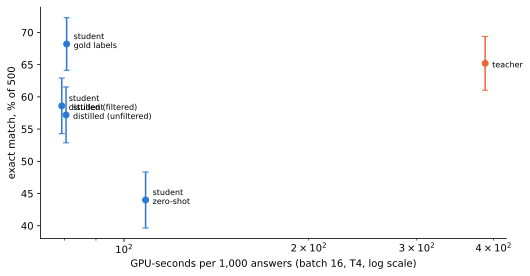

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for n in order:
    x, y = results[n]["ms per example"], results[n]["exact"] * 100
    ax.errorbar(x, y, yerr=view.loc[n, "exact ±, points"], fmt="o", color="#eb6834" if n == "teacher" else "#2a78d6", capsize=3)
    ax.annotate(n.replace("student ", "student\n"), (x, y), textcoords="offset points", xytext=(7, -4), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("GPU-seconds per 1,000 answers (batch 16, T4, log scale)")
ax.set_ylabel("exact match, % of 500")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [20]:
base, dist, gold, tchr = (results[n]["exact"] for n in ["student zero-shot", "student distilled (filtered)", "student gold labels", "teacher"])
print(f"gap between the untrained student and the teacher : {100 * (tchr - base):5.1f} points")
print(f"closed by distillation (filtered)                : {100 * (dist - base):5.1f} points = {(dist - base) / (tchr - base):.0%} of the gap")
print(f"closed by training on gold answers, same questions: {100 * (gold - base):5.1f} points = {(gold - base) / (tchr - base):.0%} of the gap")
print(f"distilled student minus teacher                  : {100 * (dist - tchr):+5.1f} points (± {view.loc['teacher', 'exact ±, points']:.1f} on each)")

# Cost. Everything is in T4 GPU-seconds, so the price is whatever the GPU costs you per second.
d_stats = train_stats["student distilled (filtered)"]
build = label_secs + d_stats["minutes"] * 60
save = (results["teacher"]["ms per example"] - results["student distilled (filtered)"]["ms per example"]) / 1000   # seconds per answer
print(f"\nto build the student : {label_secs:,.0f} s labelling + {d_stats['minutes'] * 60:,.0f} s training = {build:,.0f} GPU-seconds (once)")
print(f"saved per answer     : {save * 1000:.0f} ms of GPU time; per 1,000 answers {save * 1000:,.0f} GPU-seconds")
if save > 0:
    print(f"break-even           : after {build / save:,.0f} answers the student has paid back its labels and training")
single_t, single_s = results["teacher"].get("ms single"), results["student distilled (filtered)"].get("ms single")
if single_t and single_s:
    print(f"one request alone    : teacher {single_t:.0f} ms, student {single_s:.0f} ms ({single_t / single_s:.1f} times faster)")
print(f"memory to serve      : teacher {results['teacher']['weights GB']:.1f} GB of weights, student {results['student distilled (filtered)']['weights GB']:.1f} GB; "
      f"{results['teacher']['weights GB'] / results['student distilled (filtered)']['weights GB']:.1f} times smaller")

gap between the untrained student and the teacher :  21.2 points
closed by distillation (filtered)                :  14.6 points = 69% of the gap
closed by training on gold answers, same questions:  24.2 points = 114% of the gap
distilled student minus teacher                  :  -6.6 points (± 4.2 on each)

to build the student : 604 s labelling + 109 s training = 713 GPU-seconds (once)
saved per answer     : 308 ms of GPU time; per 1,000 answers 308 GPU-seconds
break-even           : after 2,311 answers the student has paid back its labels and training
one request alone    : teacher 1303 ms, student 646 ms (2.0 times faster)
memory to serve      : teacher 5.4 GB of weights, student 1.0 GB; 5.5 times smaller


The break-even uses the teacher's own labelling time, so it is the cost when you run the teacher yourself. When the teacher is a
paid API, the same arithmetic holds with the API's price per label in place of `label_secs`; the labels are bought once and
the student is served from your own hardware afterwards.

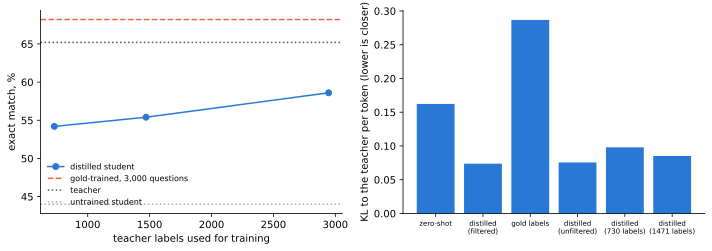

                                 KL to teacher  top-1 agreement  log-loss on teacher tokens
student zero-shot                        0.162            0.955                       0.189
student distilled (filtered)             0.074            0.975                       0.100
student gold labels                      0.287            0.947                       0.319
student distilled (unfiltered)           0.076            0.975                       0.095
student distilled (730 labels)           0.098            0.966                       0.121
student distilled (1471 labels)          0.085            0.969                       0.110


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ks = sorted(curve)
axes[0].plot(ks, [curve[k] * 100 for k in ks], "o-", color="#2a78d6", label="distilled student")
axes[0].axhline(results["student gold labels"]["exact"] * 100, color="#eb6834", linestyle="--",
                label=f"gold-trained, {N_LABEL:,} questions")
axes[0].axhline(results["teacher"]["exact"] * 100, color="#555", linestyle=":", label="teacher")
axes[0].axhline(results["student zero-shot"]["exact"] * 100, color="#aaa", linestyle=":", label="untrained student")
axes[0].set_xlabel("teacher labels used for training")
axes[0].set_ylabel("exact match, %")
axes[0].legend(frameon=False, fontsize=8)
names = [n for n in fid]
axes[1].bar(range(len(names)), [fid[n]["KL to teacher"] for n in names], color="#2a78d6")
axes[1].set_xticks(range(len(names)))
axes[1].set_xticklabels([n.replace("student ", "").replace(" (", "\n(") for n in names], fontsize=7)
axes[1].set_ylabel("KL to the teacher per token (lower is closer)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(pd.DataFrame(fid).T.round(3).to_string())

The right panel is a measurement the training never optimised: the students were trained on the teacher's text only, and this
is how far their probabilities are from the teacher's at each token of the teacher's answers (on the 50 likeliest teacher tokens, `N_FID`
test questions). The gold-trained student is a useful reference: it also learned the task, from a different source.

## 7. Does the student inherit the teacher's mistakes?

Distillation transfers behaviour. The test questions give three counts: how the student does where the teacher is right, how it
does where the teacher is wrong, and how often in the second case it writes the same wrong query as the teacher. A student that
beat its teacher would show up in the third count of questions it answers correctly while the teacher does not.

In [22]:
t = scored["teacher"]
s = scored["student distilled (filtered)"]
g = scored["student gold labels"]
same = np.array([normalise(a) == normalise(b) for a, b in zip(t["sql"], s["sql"])])
t_ok, t_bad = t["exact"].values, ~t["exact"].values
print(f"teacher right on {t_ok.sum()} of {len(t)}, wrong on {t_bad.sum()}")
print(f"distilled student right where the teacher is right : {s['exact'].values[t_ok].mean():.1%} of {t_ok.sum()}")
print(f"distilled student right where the teacher is wrong : {s['exact'].values[t_bad].mean():.1%} of {t_bad.sum()}")
print(f"distilled student writes the teacher's exact query where the teacher is wrong: {same[t_bad].mean():.1%}")
print(f"gold-trained student right where the teacher is wrong: {g['exact'].values[t_bad].mean():.1%}")
print(f"distilled student and teacher write the same query on {same.mean():.1%} of all 500 questions "
      f"(gold-trained student and teacher: {np.mean([normalise(a) == normalise(b) for a, b in zip(t['sql'], g['sql'])]):.1%})")

teacher right on 326 of 500, wrong on 174
distilled student right where the teacher is right : 77.9% of 326
distilled student right where the teacher is wrong : 22.4% of 174
distilled student writes the teacher's exact query where the teacher is wrong: 37.9%
gold-trained student right where the teacher is wrong: 39.1%
distilled student and teacher write the same query on 64.0% of all 500 questions (gold-trained student and teacher: 61.2%)


Now the same cause table as lessons 4 and 5, for the teacher and the two students trained on the full pool: **does not run**,
**wrong value or literal**, **wrong aggregate, operator or clause**, **wrong column or table**, **other**, tried in that order.

In [23]:
KEYWORDS = {"count", "sum", "avg", "min", "max", "distinct", "order", "group", "by", "desc", "asc", "limit", "having",
            "join", "union", "intersect", "except", "not", "in", "like", "between", "and", "or", "null",
            ">", "<", ">=", "<=", "=", "!=", "<>"}


def shape(sql):
    """The query with literal values removed (lesson 3)."""
    sql = re.sub(r"\"[^\"]*\"|'[^']*'", "V", sql)
    return normalise(re.sub(r"\b\d+(\.\d+)?\b", "N", sql))


def parts(sql):
    return re.findall(r"[a-z_]\w*|<>|!=|>=|<=|[=<>]", shape(sql))


def cause(row, gold, context):
    if row["error"]:
        return "does not run"
    if shape(row["sql"]) == shape(gold):
        return "wrong value or literal"
    got, want = parts(row["sql"]), parts(gold)
    if sorted(t_ for t_ in got if t_ in KEYWORDS) != sorted(t_ for t_ in want if t_ in KEYWORDS):
        return "wrong aggregate, operator or clause"
    schema = set(re.findall(r"[a-z_]\w*", context.lower())) - KEYWORDS
    if {t_ for t_ in got if t_ in schema} != {t_ for t_ in want if t_ in schema}:
        return "wrong column or table"
    return "other"


cause_names = ["teacher", "student distilled (filtered)", "student gold labels"]
for name in cause_names:
    df = scored[name]
    df["cause"] = [cause(row, r["answer"], r["context"]) if not row["exact"] else "exact match"
                   for (_, row), r in zip(df.iterrows(), test)]
order_ = ["exact match", "does not run", "wrong value or literal", "wrong aggregate, operator or clause",
          "wrong column or table", "other"]
print(pd.DataFrame({n.replace("student ", ""): scored[n]["cause"].value_counts() for n in cause_names})
      .reindex(order_).fillna(0).astype(int).to_string())

                                     teacher  distilled (filtered)  gold labels
cause                                                                          
exact match                              326                   293          341
does not run                               7                    13           15
wrong value or literal                    21                    26           25
wrong aggregate, operator or clause       73                    83           52
wrong column or table                      3                     4            2
other                                     70                    81           65


In [24]:
fails = scored["student distilled (filtered)"].query("cause != 'exact match'")
for i, row in fails.sample(min(5, len(fails)), random_state=SEED).iterrows():
    print(f"[{row['cause']}]  teacher exact: {bool(scored['teacher'].loc[i, 'exact'])}")
    print("question:", test[i]["question"])
    print("gold    :", test[i]["answer"])
    print("teacher :", scored["teacher"].loc[i, "sql"])
    print("student :", row["sql"], "\n")

[wrong aggregate, operator or clause]  teacher exact: False
question: for a Goals Against greater than 42 what is the number of losses?
gold    : SELECT AVG(losses) FROM table_name_9 WHERE goals_against > 42
teacher : SELECT losses FROM table_name_9 WHERE goals_against > 42
student : SELECT SUM(losses) FROM table_name_9 WHERE goals_against > 42 

[does not run]  teacher exact: True
question: List the names of 5 users followed by the largest number of other users.
gold    : SELECT name FROM user_profiles ORDER BY followers DESC LIMIT 5
teacher : SELECT name FROM user_profiles ORDER BY followers DESC LIMIT 5
student : SELECT name FROM user_profiles ORDER BY COUNT(followers) DESC LIMIT 5 

[wrong value or literal]  teacher exact: False
question: What is the lowest Overall for the wide receiver in a round less than 2?
gold    : SELECT MIN(overall) FROM table_name_93 WHERE position = "wide receiver" AND round < 2
teacher : SELECT MIN(overall) FROM table_name_93 WHERE position = 'WR' AND rou

## 8. What do we keep?

The adapters, the teacher's labels, and the merged student. The distilled student is a 0.5B model: after the adapter is merged into the
fp16 weights it is an ordinary model with nothing to load on top of it. The labels file is the asset that makes a second student (another size,
another recipe) cost only training time.

In [25]:
for d in ["adapter-distilled", "adapter-gold"] + (["adapter-unfiltered"] if os.path.exists("adapter-unfiltered") else []):
    print(d)
    for f in sorted(os.listdir(d)):
        print(f"  {os.path.getsize(os.path.join(d, f)) / 1e6:8.2f} MB  {f}")
    print("  base model:", json.load(open(os.path.join(d, "adapter_config.json")))["base_model_name_or_path"])
print(f"teacher_labels.json: {os.path.getsize('teacher_labels.json') / 1e6:.2f} MB, {N_LABEL:,} labels")

merged = PeftModel.from_pretrained(
    AutoModelForCausalLM.from_pretrained(STUDENT_ID, torch_dtype=DTYPE, device_map={"": DEVICE}), "adapter-distilled").merge_and_unload()
merged.save_pretrained("student-distilled-merged")
tok.save_pretrained("student-distilled-merged")
print("merged student on disk:", f"{sum(os.path.getsize(os.path.join('student-distilled-merged', f)) for f in os.listdir('student-distilled-merged')) / 1e6:.0f} MB")
del merged
free_gpu()

adapter-distilled
      0.01 MB  README.md
      0.00 MB  adapter_config.json
     35.24 MB  adapter_model.safetensors
  base model: Qwen/Qwen2.5-0.5B-Instruct
adapter-gold
      0.01 MB  README.md
      0.00 MB  adapter_config.json
     35.24 MB  adapter_model.safetensors
  base model: Qwen/Qwen2.5-0.5B-Instruct
adapter-unfiltered
      0.01 MB  README.md
      0.00 MB  adapter_config.json
     35.24 MB  adapter_model.safetensors
  base model: Qwen/Qwen2.5-0.5B-Instruct
teacher_labels.json: 0.76 MB, 3,000 labels


merged student on disk: 1004 MB


## Read the result

- **Check the gap and the cost together.** Section 6's first rows say how much of the teacher's advantage over the untrained student
  the distilled student recovered, and what it saved per answer. A student that recovers most of the gap at a fraction of the memory
  and time is the case for distillation; one that recovers little says the labels, the student size or the recipe is the limit.
- **Compare with gold answers.** The gold-trained student is the best the same questions can do with human labels. Where the
  distilled student sits between the untrained student and that row is the price of having no gold answers.
- **Read the filter honestly.** The keep rate and the unfiltered row say whether execution filtering is worth its code on this
  data. On empty tables it removes broken queries, not wrong ones; the diagnosis in section 3 shows how many kept labels are
  still not the gold query.
- **Look at the curve.** If it is still rising at the full pool, more teacher labels are the lever and the cost per label
  (section 2) sets the price; if it has flattened, the student size or the teacher's own accuracy is the limit.
- **Look at inheritance.** The counts in section 7 say whether the student's errors are the teacher's errors. A distilled student
  is bounded by what the teacher can do on questions the teacher gets wrong, unless the filter or other signals correct it.
- **The token-level panel** shows how close the probabilities came without ever being trained on them.

The lesson explains each result: [Distillation: a large model's behaviour in a small one](https://docs.recohut.com/courses/llm-fine-tuning/3-beyond-sft/09-distillation).